<a href="https://colab.research.google.com/github/Ravi-ranjan1801/Data-Warehousing-Mining-Lab/blob/main/DWM_Lab_09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Lab - 09 (Information-Theoretic Measures)**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
import zipfile
import io
import os

In [2]:
uploaded = files.upload()

zip_name = next(iter(uploaded))

DATA_DIR = "/content/dwm_data"

os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as z:
    z.extractall(DATA_DIR)

print("Dataset extracted successfully!")

Saving DWM_Practical_Datasets.zip to DWM_Practical_Datasets.zip
Dataset extracted successfully!


In [3]:
file_path = os.path.join(
    DATA_DIR,
    "06_entropy_information_gain_gini.csv"
)

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)

display(df.head(10))

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (100, 5)


,Record_ID,Outlook,Humidity,Wind,Play
0,E001,Rainy,High,Weak,No
1,E002,Sunny,High,Weak,No
2,E003,Sunny,Normal,Strong,Yes
3,E004,Rainy,High,Weak,Yes
4,E005,Cloudy,High,Strong,Yes
5,E006,Sunny,High,Strong,Yes
6,E007,Sunny,Normal,Strong,No
7,E008,Sunny,Normal,Strong,Yes
8,E009,Sunny,Normal,Weak,No
9,E010,Cloudy,Normal,Weak,Yes



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Record_ID  100 non-null    object
 1   Outlook    100 non-null    object
 2   Humidity   100 non-null    object
 3   Wind       100 non-null    object
 4   Play       100 non-null    object
dtypes: object(5)
memory usage: 4.0+ KB

Missing Values:
Record_ID    0
Outlook      0
Humidity     0
Wind         0
Play         0
dtype: int64


In [4]:
features = ['Outlook', 'Humidity', 'Wind']

target = 'Play'

X = df[features]

y = df[target]

print("Input Features:")
display(X.head())

print("\nTarget Distribution:")
print(y.value_counts())

Input Features:


,Outlook,Humidity,Wind
0,Rainy,High,Weak
1,Sunny,High,Weak
2,Sunny,Normal,Strong
3,Rainy,High,Weak
4,Cloudy,High,Strong



Target Distribution:
Play
Yes    60
No     40
Name: count, dtype: int64


In [5]:
def entropy(series):

    probabilities = series.value_counts(
        normalize=True
    )

    return -np.sum(
        probabilities * np.log2(probabilities)
    )

In [6]:
target_entropy = entropy(df['Play'])

print(
    "Entropy of Play:",
    round(target_entropy, 4)
)

Entropy of Play: 0.971


In [7]:
def joint_entropy(x, y):

    joint_probabilities = pd.crosstab(
        x,
        y,
        normalize='all'
    ).values.flatten()

    joint_probabilities = joint_probabilities[
        joint_probabilities > 0
    ]

    return -np.sum(
        joint_probabilities *
        np.log2(joint_probabilities)
    )

In [8]:
print("Joint Entropy:\n")

for feature in features:

    value = joint_entropy(
        df[feature],
        df['Play']
    )

    print(
        f"H({feature}, Play) = {value:.4f}"
    )

Joint Entropy:

H(Outlook, Play) = 2.3995
H(Humidity, Play) = 1.9402
H(Wind, Play) = 1.9589


In [9]:
def conditional_entropy(y, x):

    data = pd.DataFrame({
        'X': x,
        'Y': y
    })

    result = 0

    for value, group in data.groupby('X'):

        probability = len(group) / len(data)

        result += probability * entropy(group['Y'])

    return result

In [10]:
print("Conditional Entropy:\n")

for feature in features:

    value = conditional_entropy(
        df['Play'],
        df[feature]
    )

    print(
        f"H(Play | {feature}) = {value:.4f}"
    )

Conditional Entropy:

H(Play | Outlook) = 0.9119
H(Play | Humidity) = 0.9428
H(Play | Wind) = 0.9661


In [11]:
def information_gain(y, x):

    return entropy(y) - conditional_entropy(y, x)

In [12]:
ig_results = {}

print("Information Gain:\n")

for feature in features:

    ig = information_gain(
        df['Play'],
        df[feature]
    )

    ig_results[feature] = ig

    print(
        f"IG({feature}) = {ig:.4f}"
    )

Information Gain:

IG(Outlook) = 0.0590
IG(Humidity) = 0.0281
IG(Wind) = 0.0049


In [13]:
def mutual_information(x, y):

    return (
        entropy(x)
        + entropy(y)
        - joint_entropy(x, y)
    )

In [14]:
mi_results = {}

print("Mutual Information:\n")

for feature in features:

    mi = mutual_information(
        df[feature],
        df['Play']
    )

    mi_results[feature] = mi

    print(
        f"MI({feature}, Play) = {mi:.4f}"
    )

Mutual Information:

MI(Outlook, Play) = 0.0590
MI(Humidity, Play) = 0.0281
MI(Wind, Play) = 0.0049


In [15]:
def gini_index(series):

    probabilities = series.value_counts(
        normalize=True
    )

    return 1 - np.sum(probabilities ** 2)

In [16]:
target_gini = gini_index(df['Play'])

print(
    "Gini Index of Play:",
    round(target_gini, 4)
)

Gini Index of Play: 0.48


In [17]:
def weighted_gini(y, x):

    data = pd.DataFrame({
        'X': x,
        'Y': y
    })

    total = len(data)

    result = 0

    for value, group in data.groupby('X'):

        weight = len(group) / total

        result += weight * gini_index(
            group['Y']
        )

    return result

In [18]:
gini_results = {}

print("Weighted Gini after splitting:\n")

for feature in features:

    value = weighted_gini(
        df['Play'],
        df[feature]
    )

    gini_results[feature] = value

    print(
        f"{feature}: {value:.4f}"
    )

Weighted Gini after splitting:

Outlook: 0.4404
Humidity: 0.4615
Wind: 0.4768


In [19]:
results = []

for feature in features:

    h_feature = entropy(df[feature])

    h_joint = joint_entropy(
        df[feature],
        df['Play']
    )

    h_cond = conditional_entropy(
        df['Play'],
        df[feature]
    )

    ig = information_gain(
        df['Play'],
        df[feature]
    )

    mi = mutual_information(
        df[feature],
        df['Play']
    )

    gini = weighted_gini(
        df['Play'],
        df[feature]
    )

    results.append([
        feature,
        h_feature,
        h_joint,
        h_cond,
        ig,
        mi,
        gini,
        target_gini - gini
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        'Attribute',
        'Entropy',
        'Joint Entropy',
        'Conditional Entropy',
        'Information Gain',
        'Mutual Information',
        'Weighted Gini',
        'Gini Reduction'
    ]
)

display(results_df.round(4))

,Attribute,Entropy,Joint Entropy,Conditional Entropy,Information Gain,Mutual Information,Weighted Gini,Gini Reduction
0,Outlook,1.4876,2.3995,0.9119,0.0590,0.0590,0.4404,0.0396
1,Humidity,0.9974,1.9402,0.9428,0.0281,0.0281,0.4615,0.0185
2,Wind,0.9928,1.9589,0.9661,0.0049,0.0049,0.4768,0.0032


In [20]:
best_ig = results_df.loc[
    results_df['Information Gain'].idxmax()
]

best_gini = results_df.loc[
    results_df['Weighted Gini'].idxmin()
]

print(
    "Best Attribute using Information Gain:",
    best_ig['Attribute']
)

print(
    "Best Attribute using Gini Index:",
    best_gini['Attribute']
)

Best Attribute using Information Gain: Outlook
Best Attribute using Gini Index: Outlook


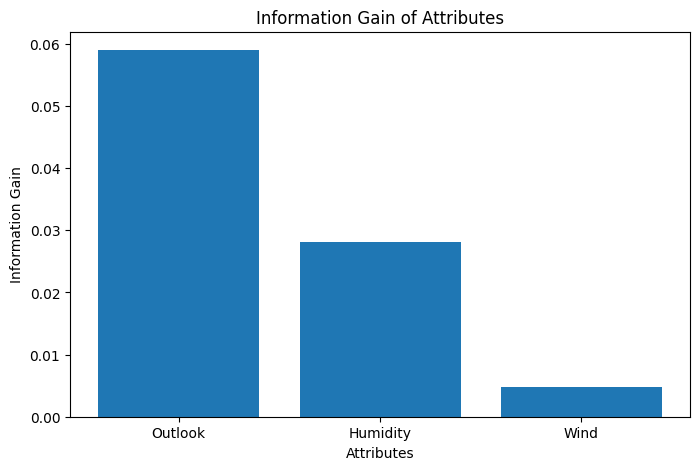

In [21]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df['Attribute'],
    results_df['Information Gain']
)

plt.title('Information Gain of Attributes')

plt.xlabel('Attributes')
plt.ylabel('Information Gain')

plt.show()

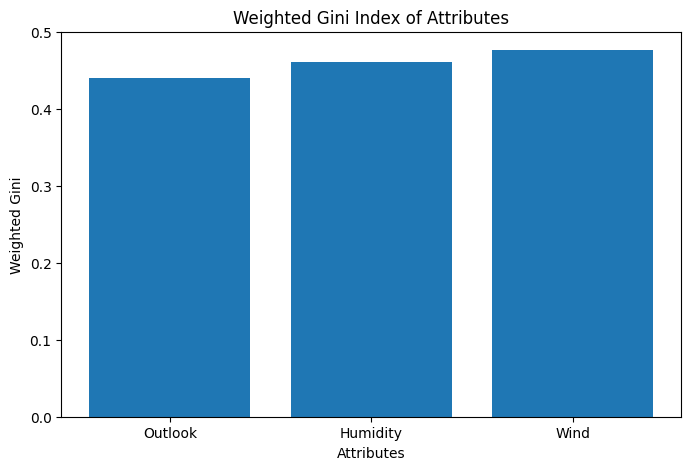

In [22]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df['Attribute'],
    results_df['Weighted Gini']
)

plt.title('Weighted Gini Index of Attributes')

plt.xlabel('Attributes')
plt.ylabel('Weighted Gini')

plt.show()

## **Conclusion**
The experiment was performed using 06_entropy_information_gain_gini.csv, with Play as the target attribute. Outlook achieved the highest Information Gain (0.0590) and the lowest weighted Gini impurity (0.4404). Therefore, Outlook is the best attribute for splitting the dataset among the three attributes considered.